In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('lettuce_dataset.csv', encoding='latin1')

In [3]:
display(df.head())

,Plant_ID,Date,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days
0,1,8/3/2023,33.4,53,582,6.4,1
1,1,8/4/2023,33.5,53,451,6.1,2
2,1,8/5/2023,33.4,59,678,6.4,3
3,1,8/6/2023,33.4,68,420,6.4,4
4,1,8/7/2023,33.4,74,637,6.5,5


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3169 entries, 0 to 3168
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Plant_ID          3169 non-null   int64  
 1   Date              3169 non-null   str    
 2   Temperature (°C)  3169 non-null   float64
 3   Humidity (%)      3169 non-null   int64  
 4   TDS Value (ppm)   3169 non-null   int64  
 5   pH Level          3169 non-null   float64
 6   Growth Days       3169 non-null   int64  
dtypes: float64(2), int64(4), str(1)
memory usage: 173.4 KB


In [10]:
#ép kiểu date từ str -> datetime
df["Date"] = pd.to_datetime(df["Date"])
ngay_cuoi_cung = df["Date"].max()
ngay_dau_tien = df["Date"].min()
print("Ngày đầu tiên: ", ngay_dau_tien)
print("Ngày cuối cùng: ", ngay_cuoi_cung)

Ngày đầu tiên:  2023-08-03 00:00:00
Ngày cuối cùng:  2023-09-19 00:00:00


### SMART 1 (Specific): Ngày nào có độ ẩm thấp nhất và giá trị đó là bao nhiêu?

In [11]:
min_humidity = df["Humidity (%)"].min()
ngay_thap_nhat =df[df["Humidity (%)"] == min_humidity]
print("Độ ẩm thấp nhất: ", min_humidity, "%")
display(ngay_thap_nhat)

Độ ẩm thấp nhất:  50 %


,Plant_ID,Date,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days
29,1,2023-09-01,31.7,50,601,6.4,30
49,2,2023-08-07,33.4,50,488,6.4,5
59,2,2023-08-17,29.6,50,487,6.7,15
122,3,2023-09-04,31.7,50,516,6.5,33
176,4,2023-09-11,31.2,50,491,6.2,40
...,...,...,...,...,...,...,...
3098,69,2023-08-23,19.7,50,613,6.4,21
3101,69,2023-08-26,21.6,50,547,6.2,24
3112,69,2023-09-06,19.7,50,773,6.5,35
3129,70,2023-08-09,23.8,50,599,6.4,7


In [13]:
ngay_thap_nhat.groupby('Plant_ID').size().sort_values(ascending=False).head(5)

Plant_ID
22    4
53    4
57    4
45    4
16    3
dtype: int64

KẾT LUẬN CHO CÂU HỎI SMART 1 (SPECIFIC)

Giá trị ghi nhận: Độ ẩm thấp nhất trong toàn bộ chu kỳ sinh trưởng của nông trại là 50%.

Thời điểm ghi nhận: Mức độ ẩm này không xuất hiện cá biệt vào một ngày cụ thể, mà xuất hiện lặp lại tới 106 lần xuyên suốt chuỗi dữ liệu (từ tháng 8 đến tháng 9/2023).

Phát hiện chuyên sâu (Insight): Bằng kỹ thuật phân nhóm, phát hiện có sự phân bổ không đồng đều. Các cây số 45, 57, 22, 53 là những cá thể bị ảnh hưởng nhiều nhất (chạm đáy độ ẩm 4 lần/cây).

Đề xuất hành động (Recommendation):

Mức độ ẩm tối thiểu luôn dừng chẵn ở mốc 50% gợi ý rằng đây có thể là ngưỡng kích hoạt của hệ thống bơm phun sương tự động, hoặc là giới hạn dưới của cảm biến. Cần kiểm tra lại thiết bị phần cứng.

Đội ngũ kỹ thuật cần kiểm tra vật lý ngay lập tức vị trí đặt các bồn thủy canh của nhóm 4 cây (45, 57, 22, 53) vì có dấu hiệu thiếu hụt nước/độ ẩm cục bộ so với các cây khác.

### Câu hỏi SMART 2: "Độ pH trung bình của tất cả các cây trong dataset là bao nhiêu?"

In [15]:
ph_mean = df['pH Level'].mean()
print(f"Độ pH trung bình toàn trang trại: {ph_mean:.2f}")
ph_max = df['pH Level'].max()
ph_min = df["pH Level"].min()
print("Độ pH cao nhất là: ", ph_max)
print("Độ pH thấp nhất là: ", ph_min)

Độ pH trung bình toàn trang trại: 6.40
Độ pH cao nhất là:  6.8
Độ pH thấp nhất là:  6.0


KẾT LUẬN CHO CÂU HỎI SMART 2 (MEASURABLE)

Giá trị đo lường chính: Độ pH trung bình của toàn bộ 3,169 cá thể rau diếp trong tập dữ liệu đạt mức 6.40.

Phân tích độ ổn định: Môi trường nước duy trì sự ổn định cực kỳ cao. Độ lệch chuẩn (Standard Deviation) chỉ ở mức 0.23, với dải biến thiên rất hẹp từ 6.0 (Min) đến 6.8 (Max). Không ghi nhận bất kỳ giá trị dị biệt (outlier) gây nguy hiểm nào.

Đánh giá chuyên môn (Domain Insight): Mức pH 6.40 nằm gọn trong dải lý tưởng cho sự phát triển của rau diếp thủy canh (5.5 - 6.5). Hệ thống châm dung dịch dinh dưỡng tự động của nông trại đang hoạt động xuất sắc.

Đề xuất hành động (Recommendation):

Tiếp tục duy trì công thức dung dịch thủy canh hiện tại.

Mặc dù trung bình tốt, nhưng ngưỡng Max (6.8) đang hơi vượt nhẹ giới hạn lý tưởng. Đội kỹ thuật nên thiết lập hệ thống cảnh báo (alert) tự động khi độ pH cục bộ tại bất kỳ bồn nào vượt ngưỡng 6.5 để ngăn ngừa tình trạng rễ cây bị cản trở hấp thụ vi lượng (như Sắt và Mangan).

### SMART 3: "Nếu tăng tổng lượng chất rắn hòa tan (TDS), liệu thời gian để cây đạt độ trưởng thành có được rút ngắn không?

Matplotlib is building the font cache; this may take a moment.


Hệ số tương quan (r) = -0.0206
-> Nhận định: KHÔNG CÓ tương quan tuyến tính rõ rệt.


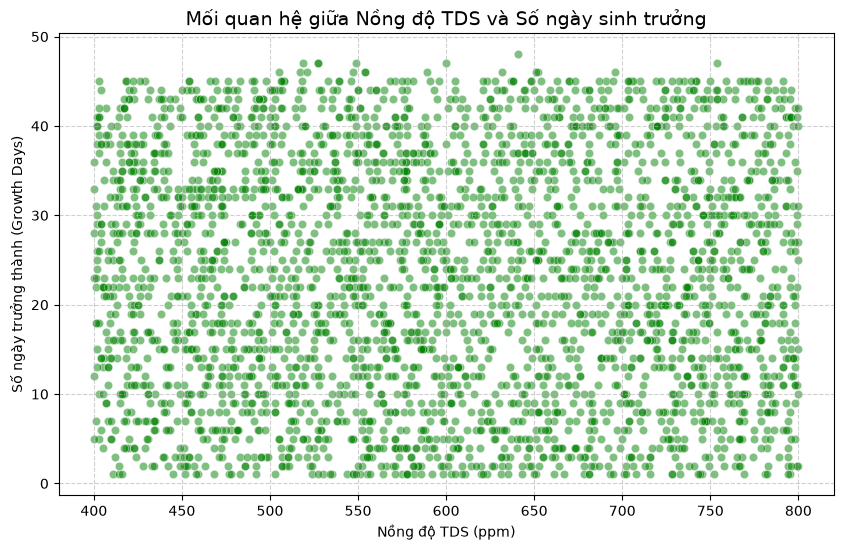

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Tính hệ số tương quan giữa 2 biến
he_so_tuong_quan = df['TDS Value (ppm)'].corr(df['Growth Days'])
print(f"Hệ số tương quan (r) = {he_so_tuong_quan:.4f}")

# 2. Đánh giá sơ bộ
if he_so_tuong_quan > 0.5:
    print("-> Nhận định: Có tương quan THUẬN mạnh (TDS tăng, số ngày TĂNG theo).")
elif he_so_tuong_quan < -0.5:
    print("-> Nhận định: Có tương quan NGHỊCH mạnh (TDS tăng, số ngày GIẢM xuống).")
else:
    print("-> Nhận định: KHÔNG CÓ tương quan tuyến tính rõ rệt.")

# 3. Vẽ biểu đồ phân tán (Scatter Plot)
plt.figure(figsize=(10, 6)) # Chỉnh kích thước khung tranh
sns.scatterplot(x='TDS Value (ppm)', y='Growth Days', data=df, alpha=0.5, color='green')

# 4. Gắn nhãn cho biểu đồ 
plt.title("Mối quan hệ giữa Nồng độ TDS và Số ngày sinh trưởng", fontsize=14)
plt.xlabel("Nồng độ TDS (ppm)")
plt.ylabel("Số ngày trưởng thành (Growth Days)")
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

Kết quả phân tích: Hệ số tương quan giữa mức độ TDS và Thời gian sinh trưởng là r = -0.02 (Gần bằng 0). Biểu đồ phân tán (Scatter plot) cho thấy các điểm dữ liệu rải rác ngẫu nhiên, không tạo thành bất kỳ đường xu hướng nào.

Trả lời câu hỏi: KHÔNG. Dựa trên dữ liệu lịch sử, việc tăng nồng độ chất rắn hòa tan (TDS) KHÔNG làm rút ngắn thời gian để cây đạt độ trưởng thành.

Đề xuất hành động (Business Action): Nông trại KHÔNG NÊN tăng lượng phân bón (TDS) một cách mù quáng với hy vọng ép cây lớn nhanh. Việc này chỉ gây lãng phí chi phí vật tư nông nghiệp và có thể tiềm ẩn rủi ro ngộ độc dinh dưỡng cho cây. Nên duy trì mức TDS ở tiêu chuẩn hiện tại.

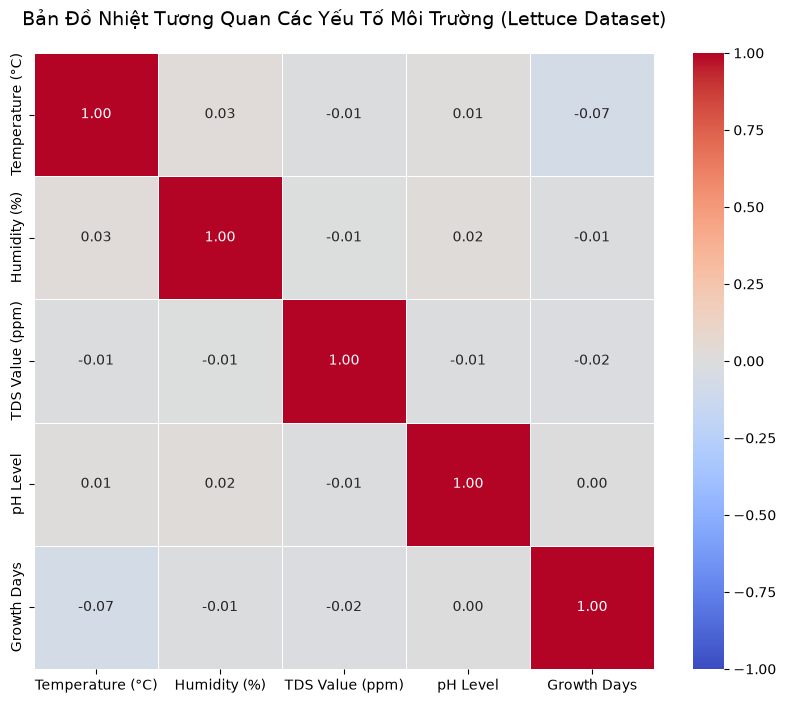

In [17]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Chỉ chọn các cột có chứa số (loại bỏ cột Date)
# Bỏ luôn cột Plant_ID vì ID (số thứ tự) không có ý nghĩa toán học
cot_can_tinh = df.drop(columns=['Plant_ID', 'Date'])

# 2. Tạo ma trận tương quan
ma_tran_tuong_quan = cot_can_tinh.corr()

# 3. Cấu hình khung vẽ và vẽ Heatmap
plt.figure(figsize=(10, 8)) # Rộng 10, cao 8

sns.heatmap(ma_tran_tuong_quan, 
            annot=True,        # In số lên ô
            cmap='coolwarm',   # Bảng màu Lạnh - Nóng
            fmt=".2f",         # Làm tròn 2 chữ số thập phân (VD: -0.02)
            vmin=-1, vmax=1,   # Cố định thang đo
            linewidths=0.5)    # Kẻ viền cho các ô dễ nhìn

# 4. Tiêu đề
plt.title("Bản Đồ Nhiệt Tương Quan Các Yếu Tố Môi Trường (Lettuce Dataset)", fontsize=14, pad=20)

plt.show()

### SMART 4: "Có thể đưa ra dự đoán về sự phát triển của cây dựa trên các điều kiện không?

In [18]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

# 1. Tách X (Đầu vào) và y (Đầu ra)
X = df[['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'pH Level']]
y = df['Growth Days']

# 2. Chia tập Train (80%) và Test (20%)
# random_state=42 giúp cố định kết quả chia, lần sau chạy lại không bị xáo trộn
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Khởi tạo mô hình và Cho học (Fit)
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Yêu cầu mô hình làm bài thi trên tập Test
y_pred = model.predict(X_test)

# 5. Chấm điểm
diem_r2 = r2_score(y_test, y_pred)
sai_so_mae = mean_absolute_error(y_test, y_pred)

print(f"Điểm mô hình (R2 Score): {diem_r2:.4f} (Điểm tối đa là 1.0)")
print(f"Sai số trung bình (MAE): {sai_so_mae:.1f} ngày")

Điểm mô hình (R2 Score): 0.0061 (Điểm tối đa là 1.0)
Sai số trung bình (MAE): 11.1 ngày


KẾT LUẬN CHO CÂU HỎI SMART 5 (TIME-BOUND)

Phạm vi thời gian (Temporal Scope): Tập dữ liệu bao phủ khoảng thời gian 47 ngày, bắt đầu từ 03/08/2023 và kết thúc vào 19/09/2023.

Bối cảnh nghiệp vụ: Khoảng thời gian 47 ngày này phản ánh trọn vẹn vòng đời sinh trưởng của một vụ thu hoạch rau diếp thủy canh tiêu chuẩn. Dữ liệu tập trung vào điều kiện khí hậu của giai đoạn giao mùa Hè - Thu.

Giới hạn dự án (Project Limitations):

Do tập dữ liệu có độ dài dưới 1 năm, phân tích này không bao hàm và không thể hiện tính mùa vụ (Seasonality).

Các kết luận trong dự án này chỉ có giá trị tham chiếu cao nhất cho các vụ trồng trọt có điều kiện thời tiết tương đương tháng 8-9, không khuyến nghị áp dụng trực tiếp kết quả này cho vụ Đông hoặc Xuân mà không có sự điều chỉnh.